<center><img src='https://drive.google.com/uc?id=1PioHCAlQTt8LWChoMysPErSOrxOfAW0R'></center>

**AI TECH - Akademia Innowacyjnych Zastosowań Technologii Cyfrowych. Programu Operacyjnego Polska Cyfrowa na lata 2014-2020**

---
<center>
<h1>Przetwarzanie multimediów w systemach decyzyjnych,</br> edycja VI-2026.</br>Informatyka, specjalność: uczenie maszynowe

Autor: Piotr Szczuko</br>

Katedra Systemów Multimedialnych</br>

</br>

15 października 2026
</center>
<h3>Laboratorium 1. Uczenie wielozadaniowe w widzeniu komputerowym, cz. 1 i 2</h2>

---

| Nazwisko wykonawcy | Nr indeksu | Termin laboratorium | Termin oddania sprawozdania |
|--------------------|------------|---------------------|---------------------|
| Józefowicz         | 193257     | 15.10.2026              | wpisać                      |



# Część 1

## Wprowadzenie

**Uczenie wielozadaniowe** to scenariusz, w którym model uczony jest więcej niż jednego zadania, spośród typowych celów, stawianych algorytmom uczenia maszynowego. Przykładowo, jedna, odpowiednio rozbudowana architektura sieci realizować może **jednocześnie** klasyfikację obiektów, lokalizację obiektów w obrazie, deskrypcję semantyczną treści obrazu, wymagającą rozumienia kontekstu, wydobywanie nowych informacji liczbowych np. wzrost w metrach na podstawie ujęcia (regresja), transformację sekwencji.

Takie zadania realizowane są typowo przez wiele osobnych modeli, jednakże integracja ich w jeden, wielozadaniowy model ma na celu zwiększyć:
- wydajność – uzyskiwane jest to poprzez współdzielenie warstw (patrz: zagadnienia uczenia on-line, dodawania kolejnych klas i zagadnień do gotowej architektury, sem. 1., specjalność: uczenie maszynowe, przedmiot: metody sztucznej inteligencji)
- zdolności generalizacji - współdzielone warstwy potencjalnie lepiej wyuczą się ekstrakcji znaczących cech, gdy cała architektura uczona będzie realizacji wielu zadań.

## Uczenie wielozadaniowe w widzeniu komputerowym - przykłady zastosowań

Dla dziedziny analizy obrazu uczenie wielozadaniowe może prowadzić do:
- Segmentacji sceny (na wyjściu wszystkie piksele obrazu otrzymują odmienne wartości-etykiety każdego obiektu)
- Lokalizacji obiektów (na wyjściu położenie ramki „bounding-box”, każdego obiektu)
- Klasyfikacji obiektów (na wyjściu etykieta klasy, każdego obiektu)
- Klasyfikacji sceny (na wyjściu etykieta klasy, całego zdjęcia)

## Współdzielenie warstw a wydajność

W wielu przypadkach decyzje dotyczące architektury modelu podyktowane muszą być kompromisem między wydajnością a dokładnością działania.

Współdzielone warstwy są tylko raz trenowane i uruchamiane na etapie wnioskowania. Jeśli będzie ich odpowiednio duży odsetek (współdzielonych  w proporcji do wszystkich) to model działać będzie wydajniej niż dwa osobne modele "jednozadaniowe".

Liczba wspólnych warstw, głębokość na której są ułożone i na której następuje rozdzielenie na gałęzie dedykowane osobnym zadaniom to hiperparametry, które regulowane być powinny w celu optymalizacji wydajności. W praktyce hiperparametry zależne będą od podobieństw między realizowanymi jednocześnie zadaniami.


## Funkcje strat w uczeniu wielozadaniowym

Cele jednocześnie realizowanych zadań mogą być odmienne i dlatego w ogólności funkcje straty dla każdego zadania mogą przyjąć inną, adekwatną do niego postać.

Wyniki `loss` należy poddać złączeniu w pojedynczy, całościowy wynik, użyteczny w procesie treningu. Złączenie może polegać na wyliczeniu sumy ważonej składowych `loss`. Optymalizacja hiperpametrów modelu obejmować może w takim przypadku także uczenie wag dla sumowania osobnych `loss`.

## Przykłady z literatury

**Architektury uczenia wielozadaniowego**

- Misra, et al., *Cross-stitch networks for multi-task learning*.
CVPR 2016

- Isikdogan L, et al., *SemifreddoNets; partially frozen neural networks for efficient computer vision systems*

**Strategie uczenia**

- Standley T, et al., *Which Tasks Should Be Learned Together in Multi-task Learning?*

Aktualizacje dla jednych zadań mogą zakłócać uczenie innych zadań (ang. Negative Transfer).

**Strategie doboru wag składowych dla funkcji loss**

- Kendall et al., *Multi-Task Learning Using Uncertainty to Weigh Losses for Scene Geometry and Semantics*, https://arxiv.org/pdf/1705.07115.pdf
- Chen et al., *GradNorm: Gradient Normalization for Adaptive Loss Balancing in Deep Multitask Networks*, https://arxiv.org/pdf/1711.02257.pdf



## Cele ćwiczenia laboratoryjnego

Zadanie polega na realizacji kroków:

1. przygotowanie 2 architektur realizujących klasyfikację obrazów ze zbioru MNIST: fully connected dla 10 cyfr, fully connected dla 3 klas (wyników dzielenia modulo 3).
1. pomiar czasu klasyfikacji
1. zapoznanie się z zasadą budowania złożonych architektur sieci
1. przygotowanie architektury do jednoczesnej klasyfikacji wielozadaniowej dla 10 cyfr oraz dla 3 klas (liczba modulo 3)
1. pomiar czasu klasyfikacji
1. próba optymalizacji architektury poprzez dobór rozmiaru części współdzielonej i części dedykowanych (pomiary czasów obliczeń, obserwacja obu wyników accuracy dla klas).

Następnie zadania powyższe powtarzane są dla architektur z warstwami splotowymi.

## Przygotowanie środowiska

Zaimportowane zostają wymagane biblioteki.

In [1]:
import numpy as np                   # obliczenia
import matplotlib.pyplot as plt      # wykresy
import random                        # generowanie liczb losowych

#from keras.datasets import mnist     # MNIST dataset
#from keras.models import Sequential  # Architektura sieci neuronowej - jednokierunkowa

#from keras.layers.core import Dense, Dropout, Activation # Warstwy sieci
#from keras.utils import np_utils                         # narzędzia NumPy
#from keras.utils.vis_utils import plot_model             # wizualizacja

import tensorflow as tf                 # TF
#from tensorflow import keras            # Keras
#from tensorflow.keras import layers     # Warstwy sieci
import keras
from keras import layers

### Wczytanie danych

Zbiór MNIST jest dostępny wprost z poziomu biblioteki Keras.

In [2]:
# MNIST to 60000 obrazów do uczenia i 10000 do testu.
# Przedstawiają cyfry pisma odręcznego, rozmiar 28·28 pikseli, jeden kanał koloru, skala szarości

print("Rozmiar danych:")
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

print("X_train", X_train.shape)
print("y_train", y_train.shape)
print("X_test", X_test.shape)
print("y_test", y_test.shape)

Rozmiar danych:
X_train (60000, 28, 28)
y_train (60000,)
X_test (10000, 28, 28)
y_test (10000,)


Przykłady ze zbioru uczącego (losowy wybór, można wykonać wielokrotnie).

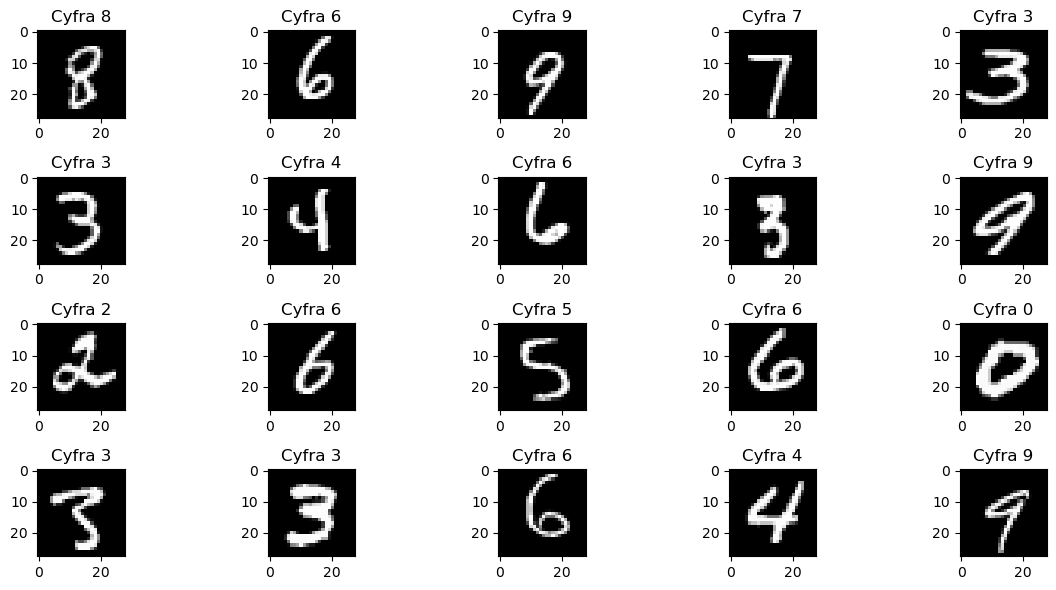

In [4]:
plt.rcParams['figure.figsize'] = (12,6)

for i in range(20):
    plt.subplot(4,5,i+1)
    num = random.randint(0, len(X_train))
    plt.imshow(X_train[num], cmap='gray', interpolation='none')
    plt.title("Cyfra {}".format(y_train[num]))

plt.tight_layout()

## Sieć wielowarstwowa - klasyfikacja cyfr do 10 klas

Dane wejściowe są wstępnie przetworzone: cyfra jest wyśrodkowana, o dość stałej wysokości, kontrastująca z tłem. Z tego powodu nie ma uzasadnienia dla stosowania warstw splotowych w sieci neuronowej - rozpoznanie takich obrazów bazować może na stwierdzaniu występowania białych pikseli w odpowiednich miejscach (właściwie: zbiorów pikseli jednocześnie występujących w określonych miejscach, silnie związanych z klasą obrazu, czyli kształtem cyfry).

Sieć przyjmować będzie na wejście wektor wszystkich pikseli 28·28=784. Dane wejściowe wymagają zmiany kształtu - operacja reshape(), (ang. flattening).

In [5]:
X_train = X_train.reshape(60000, 784) # zmiana na dane dwuwymiarowe, 60000 przykładów, 784 próbki każdy.
X_test = X_test.reshape(10000, 784)

X_train = X_train.astype('float32')   # przed normalizacją (dzieleniem przez wartość maksymalną)
X_test = X_test.astype('float32')

X_train /= 255                        # każdy piksel ma teraz wartość od 0 do 1
X_test /= 255

### Inicjalizacja modelu sieci jednokierunkowej

Zbudowana zostaje prosta trójwarstwowa sieć neuronowa, o w pełni połączonych warstwach (ang. *fully connected*). Z wykorzystaniem biblioteki `Keras` sprowadza się to do kilku poleceń z modułu layers.

In [6]:
inputs = keras.Input(shape=(784,))      # warstwa wejściowa

x = layers.Dense(64, activation="relu")(inputs) # warstwa ukryta
x = layers.Dropout(0.2)(x)
x = layers.Dense(64, activation="relu")(x)      # warstwa ukryta
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(10, name="output")(x)    # wyjście
model = keras.Model(inputs=inputs, outputs=outputs, name="mnist_model") # dobrą praktyką jest nazywać - warstwy i model

### Wizualizacja modelu

In [7]:
model.summary()
keras.utils.plot_model(model, show_shapes=True, show_layer_names=True,
           show_dtype=True,
                       dpi=100)

Model: "mnist_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │          50,240 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ output (Dense)                       │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 55,050 (215.04 KB)

 Trainable params: 55,050 (215.04 KB)

 Non-trainable params: 0 (0.00 B)

You must install pydot (`pip install pydot`) for `plot_model` to work.


### Wczytanie danych

Jeśli zajdzie potrzeba, to zastosować można poniższy, krótki blok kodu, ponownie wczytujący, zmieniający kształt i normalizujący dane.

In [13]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

x_train = x_train.reshape(60000, 784).astype("float32") / 255
x_test = x_test.reshape(10000, 784).astype("float32") / 255

### Kompilacja i trening modelu

Biblioteka Keras oferuje operację kompilowania modelu do postaci wykonywalnego grafu obliczeniowego, redukując w ten sposób narzuty związane z działaniem interpretera języka Python. Skompilowany model dzięki temu może wydajnie działać na CPU i GPU.

W trakcie kompilacji zadać należy funkcje straty i algorytm optymalizacji.

Przykładowa kros-entropia służy do pomiaru różnicy między docelowym prawdopodobieństwem, a otrzymanym prawdopodobieństwem dla wszystkich klas wyjściowych. Obliczana jest miara różnicy między rozkładem pożądanym: dana klasa 100% i każda inna klasa 0% a rozkładem zwróconym przez sieć, np. dana klasa 75%, inne klasy po 0-5%.


In [12]:
model.compile(
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    optimizer=keras.optimizers.RMSprop(),
    metrics=["accuracy"],
)

history = model.fit(x_train, y_train, batch_size=64, epochs=2, validation_split=0.2)

test_scores = model.evaluate(x_test, y_test, verbose=2)
print("Test loss:", test_scores[0])
print("Test accuracy:", test_scores[1])

Epoch 1/2
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.9415 - loss: 0.1971 - val_accuracy: 0.9611 - val_loss: 0.1303
Epoch 2/2
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9500 - loss: 0.1676 - val_accuracy: 0.9643 - val_loss: 0.1220
313/313 - 1s - 4ms/step - accuracy: 0.9652 - loss: 0.1215
Test loss: 0.12153016030788422
Test accuracy: 0.9652000069618225


Wywołane powyżej polecenie `model.fit` przeprowadza proces treningu na danych podanych jako argumenty, z zadanymi hiperparametrami rozmiaru paczki `batch`, liczby epok, wielkości zbioru walidacyjnego.

Zasady uczenia sieci neuronowych przedstawione były w ramach innych przedmiotów 1. semestru i tu nie są wyjaśniane w szczegółach.

### Ocena modelu

Po zakończonym `model.fit` automatycznie uruchamiane jest wnioskowanie na danych uczących i powyżej zaobserwować można wartości loss i accuracy.

Polecenie `model.evaluate` pozwala uruchomić wnioskowanie (ang. inference) na nowych danych, w tym wypadku `x_test` i klasy `y_test`. Otrzymywane są inne wartości loss i acccuracy, adekwatne do oceny działania modelu w rzeczywistości.




In [ ]:
score = model.evaluate(x_test, y_test)
print('Test loss:', score[0])
print('Test accuracy:', score[1])

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9567 - loss: 0.1469
Test loss: 0.14688479900360107
Test accuracy: 0.9567000269889832


In [15]:
import time

runs_number = 10
training_times = []
evaluation_times = []

for i in range(runs_number):
    (x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

    x_train = x_train.reshape(60000, 784).astype("float32") / 255
    x_test = x_test.reshape(10000, 784).astype("float32") / 255

    model.compile(
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        optimizer=keras.optimizers.RMSprop(),
        metrics=["accuracy"],
    )

    # model training time measurement
    start_time = time.time()

    history = model.fit(x_train, y_train, batch_size=64, epochs=2, validation_split=0.2)

    end_time = time.time()
    training_time = end_time - start_time
    print(f"Training time: {training_time:.2f} seconds")
    training_times.append(training_time)

    # model evaluation time measurement
    start_time = time.time()

    test_scores = model.evaluate(x_test, y_test, verbose=2)

    end_time = time.time()
    evaluation_time = end_time - start_time
    print(f"Evaluation time: {evaluation_time:.2f} seconds")
    evaluation_times.append(evaluation_time)

    print(f"Test loss: {test_scores[0]}")
    print(f"Test accuracy: {test_scores[1]}")

average_training_time = sum(training_times) / len(training_times)
average_evaluation_time = sum(evaluation_times) / len(evaluation_times)

print(f"Average training time over {runs_number} runs: {average_training_time:.2f} seconds")
print(f"Average evaluation time over {runs_number} runs: {average_evaluation_time:.2f} seconds")

Epoch 1/2
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - accuracy: 0.9606 - loss: 0.1352 - val_accuracy: 0.9691 - val_loss: 0.1112
Epoch 2/2
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9623 - loss: 0.1266 - val_accuracy: 0.9713 - val_loss: 0.1065
Training time: 15.00 seconds
313/313 - 2s - 5ms/step - accuracy: 0.9734 - loss: 0.0999
Evaluation time: 1.87 seconds
Test loss: 0.09986462444067001
Test accuracy: 0.9733999967575073
Epoch 1/2
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.9631 - loss: 0.1261 - val_accuracy: 0.9709 - val_loss: 0.1051
Epoch 2/2
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9659 - loss: 0.1201 - val_accuracy: 0.9723 - val_loss: 0.1002
Training time: 19.10 seconds
313/313 - 1s - 4ms/step - accuracy: 0.9729 - loss: 0.1009
Evaluation time: 1.54 seconds
Test loss: 0.10087326914072037
Test accuracy: 0.9728999733924866
Epoch 1/2
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.9664 - loss: 0.1166 - val_accuracy: 0.9719 - val_loss: 0.1081
E

### Zadanie do wykonania

Powtórzyć należy kilkukrotnie trening oraz ewaluację, odnotowując czasy działania.

# Podsumowanie zadania do wykonania:

Liczba powtórzeń: `10`

Średni czas treningu: `16.26 seconds`

Średni czas ewaluacji: `1.75 seconds`

## Uczenie wielozadaniowe

### Definicja dodatkowego zadania

W celu zapoznania z zasadami budowy i treningu sieci wielozadaniowych, zaproponowane jest trywialne zagadnienie dwuwyjściowej sieci:

- pierwsze wyjście określa cyfrę, jak powyżej od 0 do 9,
- drugie wyjście podaje inne klasy - przykładowo wynik `y mod 3` (w składni Pythona `y % 3`)

W rzeczywistych zagadnieniach zadania nie powinny być tak ściśle powiązane ze sobą (patrz: rozdział pierwszy tego notatnika). Tu wykorzystywany jest zbiór 70000 obrazów o jednej etykiecie, dla którego ręczne przygotowanie etykiet nowego zadania (np. dla klasyfikacji między cyframi napisanymi starannie/niestarannie) byłoby zbyt czasochłonne.


In [16]:
nb_classes = 3 # liczba klas drugiego zadania

y2_train = y_train % nb_classes
y2_test = y_test % nb_classes

print("Oryginalne klasy:")
print(y_train[0:12])

print("Nowe klasy:")
print(y2_train[0:12])

Oryginalne klasy:
[5 0 4 1 9 2 1 3 1 4 3 5]
Nowe klasy:
[2 0 1 1 0 2 1 0 1 1 0 2]


### Zadanie do wykonania - budowa modelu dla drugiego zagadnienia

Na podstawie powyższego kodu dla modelu sieci klasyfikującej do 10 klas należy:
- przygotować **model jednozadaniowy**, realizujący klasyfikację zbioru MNIST do klas 0, 1 i 2 w zależności od wyniku `x % 3`. `x_train, x_test` pozostają bez zmian, a klasy `y2_train, y2_test`.
- maksymalnie uprościć architekturę zmniejszając liczbę warstw i ich rozmiar (szerokość), zachowując odpowiednio **wysokie `accuracy`**
- pomierzyć czasy działania - nauki i ewaluacji

In [17]:
import time

nb_classes = 3 # liczba klas drugiego zadania

y_modulo_train = y_train % nb_classes
y_modulo_test = y_test % nb_classes

print("Oryginalne klasy:")
print(y_train[0:12])

print("Nowe klasy:")
print(y_modulo_train[0:12])

# modulo model
inputs = keras.Input(shape=(784,))      # warstwa wejściowa

x = layers.Dense(64, activation="relu")(inputs) # warstwa ukryta
x = layers.Dropout(0.2)(x)
x = layers.Dense(64, activation="relu")(x)      # warstwa ukryta
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(10, name="output")(x)    # wyjście
modulo_model = keras.Model(inputs=inputs, outputs=outputs, name="modulo_model")

runs_number = 2
training_times = []
evaluation_times = []

for i in range(runs_number):
    (x_train, y_modulo_train), (x_test, y_modulo_test) = keras.datasets.mnist.load_data()

    x_train = x_train.reshape(60000, 784).astype("float32") / 255
    x_test = x_test.reshape(10000, 784).astype("float32") / 255

    modulo_model.compile(
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        optimizer=keras.optimizers.RMSprop(),
        metrics=["accuracy"],
    )

    # model training time measurement
    start_time = time.time()

    history = modulo_model.fit(x_train, y_modulo_train, batch_size=64, epochs=2, validation_split=0.2)

    end_time = time.time()
    training_time = end_time - start_time
    print(f"Training time: {training_time:.2f} seconds")
    training_times.append(training_time)

    # model evaluation time measurement
    start_time = time.time()

    test_scores = modulo_model.evaluate(x_test, y_modulo_test, verbose=2)

    end_time = time.time()
    evaluation_time = end_time - start_time
    print(f"Evaluation time: {evaluation_time:.2f} seconds")
    evaluation_times.append(evaluation_time)

    print(f"Test loss: {test_scores[0]}")
    print(f"Test accuracy: {test_scores[1]}")

average_training_time = sum(training_times) / len(training_times)
average_evaluation_time = sum(evaluation_times) / len(evaluation_times)

print(f"Average training time over {runs_number} runs: {average_training_time:.2f} seconds")
print(f"Average evaluation time over {runs_number} runs: {average_evaluation_time:.2f} seconds")

Oryginalne klasy:
[5 0 4 1 9 2 1 3 1 4 3 5]
Nowe klasy:
[2 0 1 1 0 2 1 0 1 1 0 2]
Epoch 1/2
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - accuracy: 0.8503 - loss: 0.4933 - val_accuracy: 0.9446 - val_loss: 0.1937
Epoch 2/2
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9266 - loss: 0.2480 - val_accuracy: 0.9543 - val_loss: 0.1565
Training time: 19.13 seconds
313/313 - 1s - 4ms/step - accuracy: 0.9535 - loss: 0.1582
Evaluation time: 1.53 seconds
Test loss: 0.1581932157278061
Test accuracy: 0.953499972820282
Epoch 1/2
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.9397 - loss: 0.2019 - val_accuracy: 0.9625 - val_loss: 0.1326
Epoch 2/2
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9481 - loss: 0.1759 - val_accuracy: 0.9647 - val_loss: 0.1216
Training time: 13.73 seconds
313/313 - 1s - 5ms/step - accuracy: 0.9662 - loss: 0.1128
Evaluation time: 1.61 seconds
Test loss: 0.1128341406583786
Test accuracy: 0.9661999940872192
Average training time over 2 runs: 16.43 seconds


### Budowa modelu wielozadaniowego

Biblioteka `keras` oferuje intuicyjny sposób budowy architektury sieci w formie grafu, w którym możliwe są połączenia wyjść z wielu warstw, rozdzielenia wyjść i inne. Szczegóły dostępne są w dokumentacji: https://keras.io/guides/functional_api/

Poniżej zaproponowany jest model sieci jednocześnie klasyfikującej cyfry do klas 0-9 oraz do klas 0, 1, 2.

Należy zwrócić uwagę na obiekt nazwany 'split', tj. wyjście pierwszej warstwy dense i na sposób w jaki użyty jest jako wejście do dwóch różnych gałęzi. Prześledzić należy kod oraz wykreślony graf.

(jeśli samodzielnie nie nadano nazw `name="nazwa"` to stosowane są domyślne, rozróżniane inkrementowanym numerem)


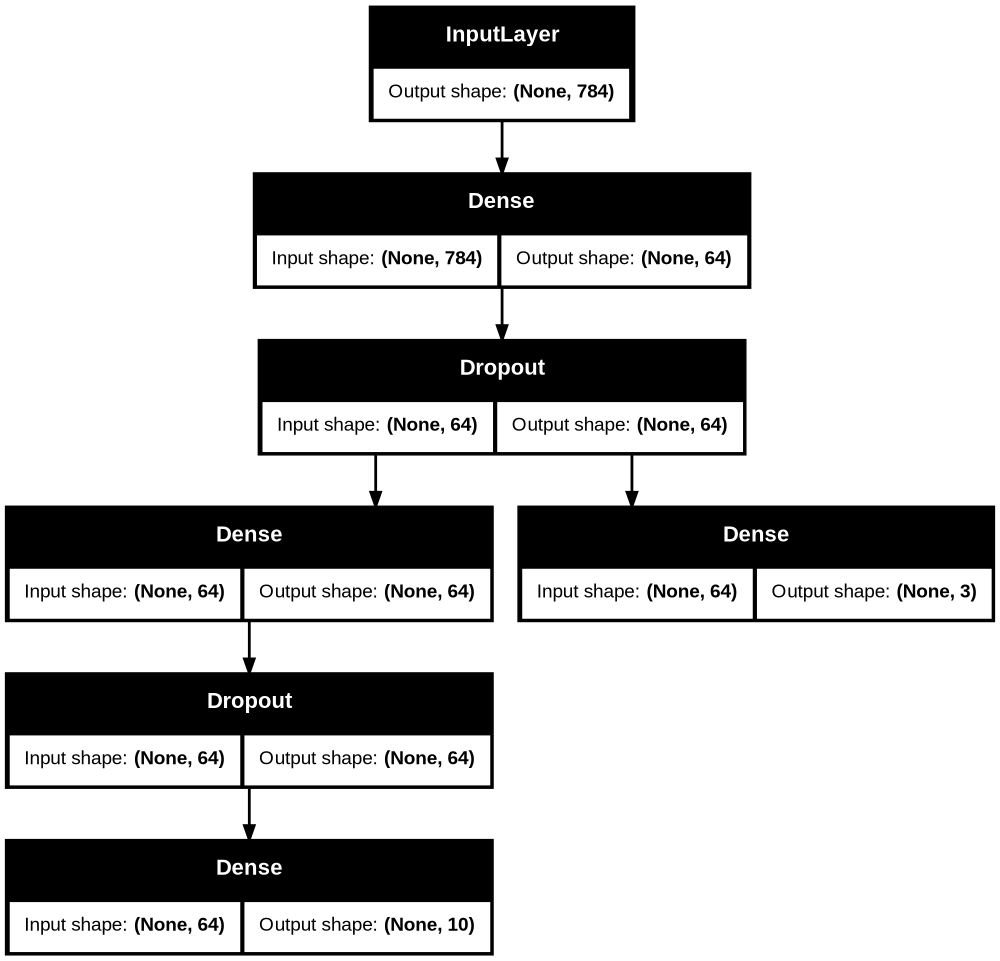

In [11]:
inputs = keras.Input(shape=(784,))

x = layers.Dense(64, activation="relu")(inputs)
split = layers.Dropout(0.2)(x)

x10 = layers.Dense(64, activation="relu")(split)
x10 = layers.Dropout(0.2)(x10)


outputs10 = layers.Dense(10, name="numbers")(x10)

outputs3 = layers.Dense(3, name="modulo")(split)

model = keras.Model(inputs=inputs,
                    outputs=[outputs10, outputs3],)

keras.utils.plot_model(model,show_shapes=True, dpi=100)

Model należy skompilować, definiując `loss` i `loss_weights` jako dwuelementowe słowniki Pythona o kluczach tożsamych z nazwami warstw wyjściowych.

In [12]:
model.compile(
    loss={
        "numbers": keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        "modulo": keras.losses.SparseCategoricalCrossentropy(from_logits=True)
    },
    loss_weights={"numbers": 1.0, "modulo": 0.5},
    optimizer=keras.optimizers.RMSprop(1e-3),
    metrics=["accuracy","accuracy"]
)

Model zostaje wyuczony. Należy zwrócić uwagę na argument `y`, który jest wektorem dwóch wyjść.

In [13]:
model.fit(x=x_train,
          #y={"numbers": y_train, "modulo": y2_train},
          y=[y_train, y2_train],
          batch_size=64, epochs=2, validation_split=0.2
          )

Epoch 1/2
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - loss: 0.6684 - modulo_accuracy: 0.8660 - modulo_loss: 0.3534 - numbers_accuracy: 0.8547 - numbers_loss: 0.4917 - val_loss: 0.2794 - val_modulo_accuracy: 0.9479 - val_modulo_loss: 0.1678 - val_numbers_accuracy: 0.9437 - val_numbers_loss: 0.1950
Epoch 2/2
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.3432 - modulo_accuracy: 0.9337 - modulo_loss: 0.1923 - numbers_accuracy: 0.9264 - numbers_loss: 0.2470 - val_loss: 0.2174 - val_modulo_accuracy: 0.9599 - val_modulo_loss: 0.1258 - val_numbers_accuracy: 0.9551 - val_numbers_loss: 0.1540


## Zadanie do wykonania - Ocena działania modelu

Podobnie jak w etapie uczenia, w trakcie ewaluacji modelu należy podać wektor dwóch odpowiedzi y_test i y2_test. Zwrócić należy uwagę na otrzymany wynik - wektor wartości całkowitego loss, loss zagadnienia pierwszego, loss zagadnienia drugiego, accuracy pierwszego i accuracy drugiego.

Ewaluację należy powtórzyć kilkukrotnie odnotowując czasy.
Czy czasy są dłuższe/krótsze od sumy czasów działania modeli jednozadaniowych?




In [14]:
score = model.evaluate(x_test, [y_test, y2_test])
print(score)


313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.2107 - modulo_accuracy: 0.9597 - modulo_loss: 0.1283 - numbers_accuracy: 0.9568 - numbers_loss: 0.1463
[0.21066933870315552, 0.14627104997634888, 0.1283262073993683, 0.9596999883651733, 0.9567999839782715]


## Zadanie do wykonania - optymalizacja modelu wielozadaniowego

Należy skopiować kod budowy modelu, kompilacji, uczenia i ewaluacji do komórki poniżej. Modyfikować architekturę sieci, miejsce rozgałęzienia, szerokości warstw, liczbę warstw i utworzyć model o mniejszej liczbie wag, realizujący oba zadania z wysokim accuracy.

## Sieci splotowe

In [15]:
#from keras.preprocessing.image import ImageDataGenerator
#from keras.layers import Conv2D, MaxPooling2D, ZeroPadding2D, GlobalAveragePooling2D, Flatten
#from keras.layers.normalization.batch_normalization import BatchNormalization

### Wczytanie zbioru danych

Dla sieci splotowych wejściem powinny być tensory - macierze wielowymiarowe, dlatego nie ma potrzeby zmiany kształtu. Jednakże konieczne jest podanie wprost informacji o czwartym wymiarze - liczbie kanałów koloru. W tym wypadku wymiary tensora to `60 000, 28, 28, 1`.

In [16]:
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

X_train = X_train.reshape(60000, 28, 28, 1)
X_test = X_test.reshape(10000, 28, 28, 1)

X_train = X_train.astype('float32')
X_test = X_test.astype('float32')

X_train /= 255
X_test /= 255

W poniższym przykładzie zastosowane jest kodowanie one-hot (one versus all).

In [17]:
nb_classes = 10 # number of unique digits

Y_train = keras.utils.to_categorical(y_train, nb_classes)
Y_test = keras.utils.to_categorical(y_test, nb_classes)

In [18]:
print(Y_test)

[[0. 0. 0. ... 1. 0. 0.]
 [0. 0. 1. ... 0. 0. 0.]
 [0. 1. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


Poniżej jako argumenty podawane są nienazwane parametry, jednakże zachowana jest kolejność:

- pierwszy argument - liczba filtrów,
- drugi argument - rozmiar kwadratowego kernela, np. 3 oznacza 3x3.

In [19]:
inputs = keras.Input(shape=(28, 28, 1), name="img")
# layers.Conv2D - własne zadanie: sprawdzić dokumentację przez użycie 'tooltip' i autouzupełniania
x = layers.Conv2D(32, 3, activation="relu")(inputs)
x = layers.Conv2D(64, 3, activation="relu")(x)
x = layers.MaxPooling2D(3)(x)

x = layers.Conv2D(64, 3, activation="relu", padding="same")(x)
x = layers.Conv2D(64, 3, activation="relu", padding="same")(x)
x = layers.GlobalAveragePooling2D()(x)

x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(10)(x)

model = keras.Model(inputs, outputs)
model.summary()
#keras.utils.plot_model(model, show_shapes=True,dpi=100)

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ img (InputLayer)                │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │        16,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,882 (437.04 KB)

 Trainable params: 111,882 (437.04 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
model.compile(
    optimizer=keras.optimizers.RMSprop(1e-3),
    loss=keras.losses.CategoricalCrossentropy(from_logits=True),
    metrics=["acc"],
)

model.fit(X_train, Y_train, batch_size=64, epochs=1, validation_split=0.2)

750/750 ━━━━━━━━━━━━━━━━━━━━ 14s 9ms/step - acc: 0.6645 - loss: 0.9542 - val_acc: 0.9479 - val_loss: 0.1834


In [21]:
score = model.evaluate(X_test, Y_test)

print('Test loss:', score[0])
print('Test accuracy:', score[1])

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - acc: 0.9511 - loss: 0.1734
Test loss: 0.1734207719564438
Test accuracy: 0.9510999917984009


## Zadanie do wykonania

Należy skopiować cały kod związany z budowaniem, nauką i ewaluacją sieci splotowej i **zmodyfikować go do działania wielozadaniowego**. Wykorzystać można jako drugie zadanie określone wcześniej trywialne klasy `x mod 3`.

Model należy wyświetlić `plot_model(model)`.
Spróbować uprościć uzyskany model, zmniejszając liczbę filtrów i warstw.

Na koniec należy przebadać i opisać działanie wykonanych wariantów.

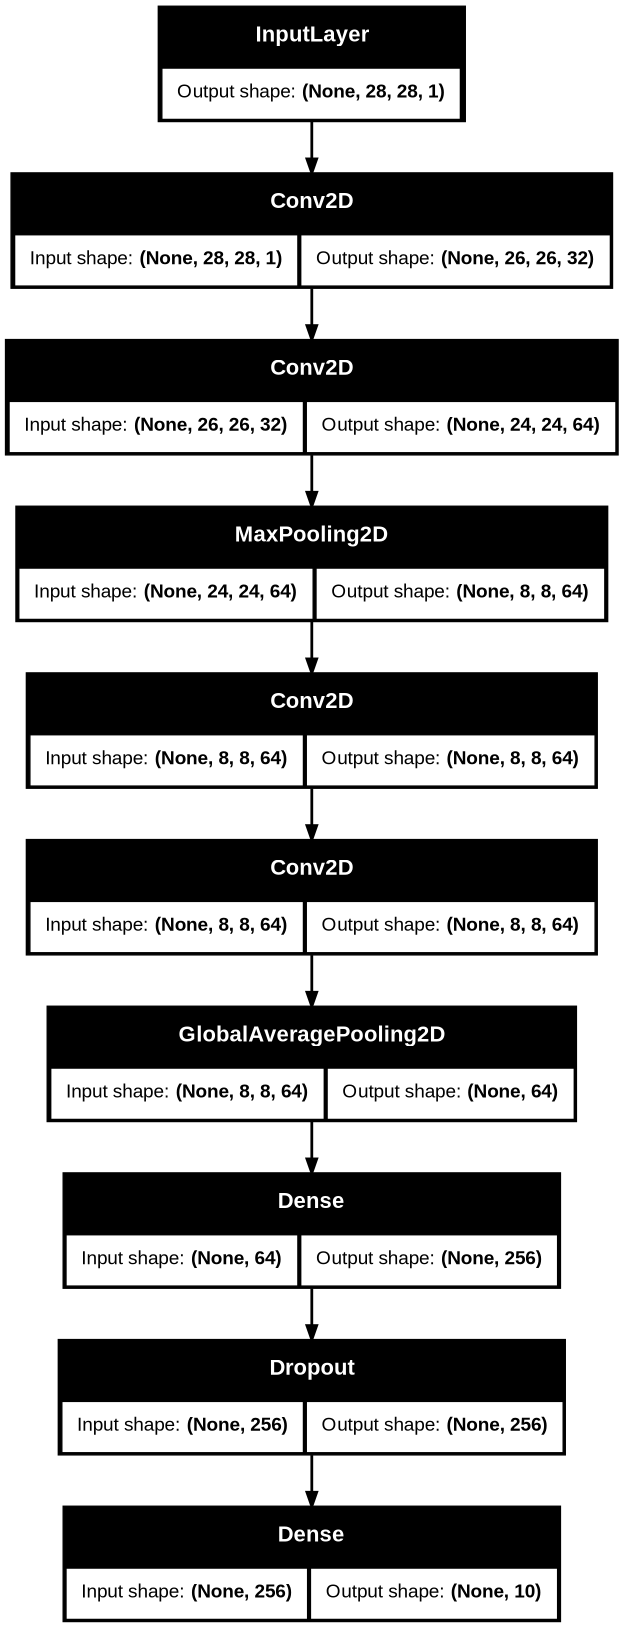

In [22]:
keras.utils.plot_model(model,show_shapes=True, dpi=100)

# Część 2

Celem części 2 jest:

- przygotowanie nowych danych dla zbioru obrazów CIFAR-10 (10 klas przedmiotów, obrazy kolorowe 32·32 piksele) i dla zadania regresji - wyliczania wartości koloru (ang. `hue`) ze średnich wartości pikseli obrazów w przestrzeni kolorów R,G,B,
- przygotowanie, trening i test architektury jednozadaniowej, dedykowanej do regresji - określania wartości `hue`
- przygotowanie, trening i test architektury jednozadaniowej, dedykowanej oryginalnemu zadaniu: klasyfikacji obrazów do jednej z 10 klas
- połączenie obu zadań w scenariuszu uczenia wielozadaniowego: dyskusja i propozycja `loss` oraz metryki dokładności
- optymalizacja scenariusza poprzez zastosowanie pre-trenowania, rozbudowania architektury, zamrożenia wag wybranej części architektury, dotrenowanie i test uzyskiwanego modelu.

# Zagadnienia teoretyczne

Optymalny trening modeli wymaga doboru właściwych wartości hiperparametrów. Część pierwsza dotyczyła budowy i testowania odmiennych architektur, część druga, obecnie realizowana, wymaga doboru wag indywidualnych funkcji loss w obu zadaniach, doboru tempa uczenia, doboru warstw poddawanych zamrożeniu i innych.

## Dobór wag loss

Trening modelu przebiega w oparciu o obserwację zmian funkcji loss. W uczeniu wielozadaniowym loss jest wieloskładnikowy, tj. wymaga wyliczenia sumy, sumy ważonej lub innej skumulowanej wartości, wyrażającej poprawę modelu w jednoczesnej realizacji obu zadań.

Jeśli zadania mają odmienną naturę, np. regresja i klasyfikacja, to sposób pomiaru ich działania będzie odmienny. Zarówno metryki (błąd średni, błąd średniokwadratowy, dokładność klasyfikacji, itd.) jak i loss będą odmienne i dobrane muszą być z rozwagą i celowo.

Wskazówka praktyczna: warto stworzyć i rozpocząć trening modelu jednozadaniowego, aby zaobserwować wartości loss i błędów, zachodzące dla danego zagadnienia. Różnice w skalach wartości mogą być korygowane **doborem odpowiednich wag dla loss**.

Brak zbalansowania między wagami prowadzi do lepszej i szybszej nauki jednego z zadań kosztem pomijania poprawy w treningu drugiego zadania.

## Dobór prędkości nauki

Wartość *learning rate* jest jednym z najważniejszych hiperparametrów, wpływających na konwergencję modelu (zbieganie konsekwentne do stanu optymalnego). Dla odmiennych zadań wartość `lr` będzie generalnie różna. Odpowiednia dla jednego ale zbyt duża dla drugiego zadania, powodować będzie eksplozję gradientów i brak konwergencji. Odpowiednia dla drugiego ale zbyt mała dla pierwszego zadania, powodować będzie zbyt wolne tempo konwergencji i potrzebę wydłużenia procesu treningu.

Dostępne jest wiele różnorodnych scenariuszy *multi-task learning*, które pozwalają na przykład na naprzemienny trening części większego modelu danymi jednego i drugiego zadania. Więcej: *Alternate training, MTL in tensorflow:* https://jg8610.github.io/Multi-Task/

# Wymagania wstępne

Wykonanie laboratorium należy rozpocząć od **przypomnienia zagadnień z pierwszej części**, realizowanej na poprzednich zajęciach. W instrukcji do cz. 1 dostępne są opisy i wyjaśnienia, które są istotne dla scenariuszy uczenia wielozadaniowego i dla rozbudowy modeli, ale nie są tutaj ponownie zamieszczane.

## Przygotowanie środowiska

Następuje zaimportowanie wymaganych modułów z bibliotek tensorflow, keras i numpy.

In [1]:
#importowanie bibliotek

import tensorflow as tf
import numpy as np
#from tensorflow.keras import layers
#from keras.utils.vis_utils import plot_model
import matplotlib.pyplot as plt      # wykresy
import random                        # generowanie liczb losowych

#from keras.datasets import mnist     # MNIST dataset
#from keras.models import Sequential  # Architektura sieci neuronowej - jednokierunkowa

#from keras.layers.core import Dense, Dropout, Activation # Warstwy sieci
#from keras.utils import np_utils                         # narzędzia NumPy
#from keras.utils.vis_utils import plot_model             # wizualizacja

#from tensorflow import keras            # Keras
#from tensorflow.keras import layers     # Warstwy sieci
import keras
from keras import layers

In [ ]:
# pobranie zbioru danych - pół godziny pobierania z oryginalnego źródła
#(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()


In [3]:
# alternatywne źródło - kaggle
import kagglehub

# Download latest version
path = kagglehub.dataset_download("hieunm44/cifar-10-python-tar-gz")

print("Path to dataset files:", path)

100%|██████████| 162M/162M [00:04<00:00, 36.8MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/hieunm44/cifar-10-python-tar-gz/versions/1


In [4]:
import os
import pickle
import numpy as np

# List the files in the downloaded dataset path
print("Files in dataset directory:")
for root, dirs, files in os.walk(path):
    print(f"Root: {root}")
    print(f"Dirs: {dirs}")
    print(f"Files: {files}")

def load_cifar10_batch(file_path):
    with open(file_path, 'rb') as f:
        entry = pickle.load(f, encoding='latin1')
        features = entry['data']
        labels = entry['labels']
        # Reshape to (num_samples, channels, height, width) and transpose to (num_samples, height, width, channels)
        features = features.reshape(10000, 3, 32, 32).transpose(0, 2, 3, 1)
        return features, np.array(labels)

# Locating the actual cifar-10-batches-py subdirectory dynamically
batch_dir = None
for root, dirs, files in os.walk(path):
    if 'data_batch_1' in files:
        batch_dir = root
        break

if batch_dir:
    print(f"Found batch directory at: {batch_dir}")

    # Load training batches
    x_train_list = []
    y_train_list = []
    for i in range(1, 6):
        batch_path = os.path.join(batch_dir, f'data_batch_{i}')
        x_b, y_b = load_cifar10_batch(batch_path)
        x_train_list.append(x_b)
        y_train_list.append(y_b)

    X_train = np.concatenate(x_train_list, axis=0)
    y_train = np.concatenate(y_train_list, axis=0)

    # Load test batch
    test_batch_path = os.path.join(batch_dir, 'test_batch')
    X_test, y_test = load_cifar10_batch(test_batch_path)

    print(f"X_train shape: {X_train.shape}")
    print(f"y_train shape: {y_train.shape}")
    print(f"X_test shape: {X_test.shape}")
    print(f"y_test shape: {y_test.shape}")
else:
    print("Could not automatically locate CIFAR-10 data batches. Please ensure the dataset contains the raw batch files.")


Files in dataset directory:
Root: /root/.cache/kagglehub/datasets/hieunm44/cifar-10-python-tar-gz/versions/1
Dirs: ['cifar-10-batches-py']
Files: []
Root: /root/.cache/kagglehub/datasets/hieunm44/cifar-10-python-tar-gz/versions/1/cifar-10-batches-py
Dirs: []
Files: ['readme.html', 'data_batch_4', 'test_batch', 'batches.meta', 'data_batch_5', 'data_batch_1', 'data_batch_2', 'data_batch_3']
Found batch directory at: /root/.cache/kagglehub/datasets/hieunm44/cifar-10-python-tar-gz/versions/1/cifar-10-batches-py
X_train shape: (50000, 32, 32, 3)
y_train shape: (50000,)
X_test shape: (10000, 32, 32, 3)
y_test shape: (10000,)


In [6]:
#normalizacja


x_train = X_train.astype('float32') / 255.0
x_test = X_test.astype('float32') / 255.0

## Wizualizacja danych


Dla przypomnienia: tensory (macierze wielowymiarowe) dla obrazów kolorowych posiadają 4 wymiary: numer próbki, kolumny, wiersze, numer kanału koloru. Dane wyjściowe także są tensorem, macierzą dwuwymiarową: numer próbki, numer cechy - w tym wypadku jedna klasa przydzielana obrazowi.

Zaobserwować można rozmiar wczytanych danych:

In [7]:
print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)

(50000, 32, 32, 3)
(50000,)
(10000, 32, 32, 3)
(10000,)


In [8]:
from matplotlib import pyplot
%matplotlib inline

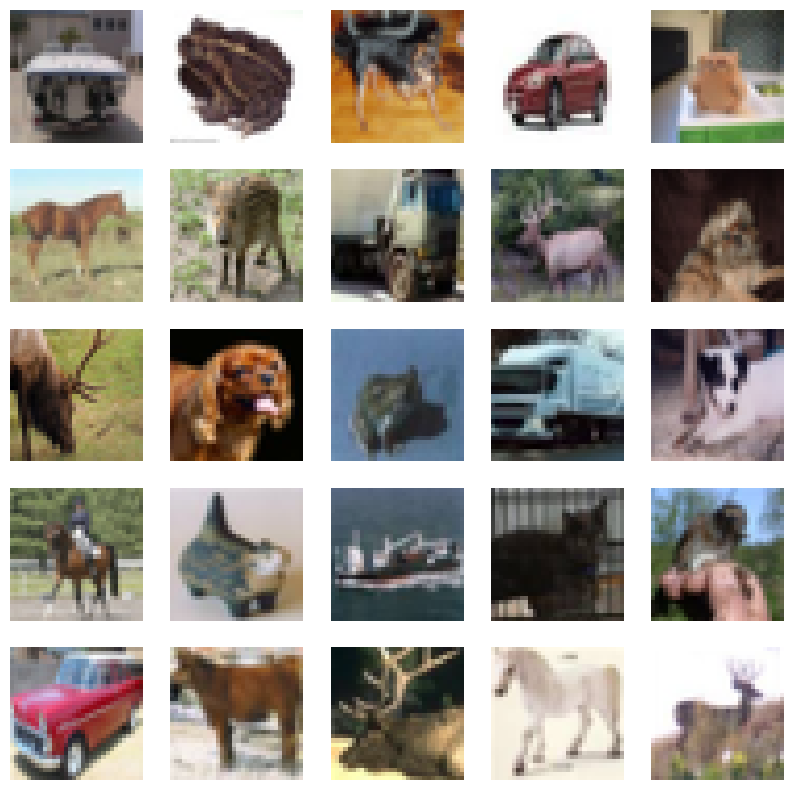

In [9]:
fig, axes = pyplot.subplots(5,5,figsize=(10,10))
for j in range(5):
    for k in range(5):
        i = np.random.choice(range(len(x_train)))
        axes[j][k].set_axis_off()
        axes[j][k].imshow(x_train[i:i+1][0])

# Zadania dla uczenia wielozadaniowego

## Zadanie oryginalne

Na podstawie obrazów modele mają za zadanie określać jedną z 10 klas: airplanes, cars, birds, cats, deer, dogs, frogs, horses, ships, trucks. Dane wyjściowe `y_train` i `y_test` posiadają odpowiedni numer klasy (kodowanie wprost jedną liczbą `int`).

Klasyfikację wykonać można sieciami neuronowymi w pełni połączonymi lub splotowymi. Uzyskiwane wyniki to kilka procent błędów klasyfikacji (https://en.wikipedia.org/wiki/CIFAR-10#Research_papers_claiming_state-of-the-art_results_on_CIFAR-10).

## Zadanie dodatkowe

Na potrzeby scenariusza uczenia wielozadaniowego przygotowane zostaną nowe dane wyjściowe. Zadanie ma polegać na określaniu odcienia kolorów obrazu. W przestrzeni barw HSV pierwszy wymiar to odcień, ang. hue, jednoznaczny z tym, jak opisujemy kolor jednym słowem: czerwony, zielony, itp. Pozostałe, które tu są ignorowane to S-saturacja (nasycenie barwy - intensywna, blada) oraz V-value (jasność).

Skalę odcieni prezentuje poniższy rysunek, wartości wyrażane są w stopniach.

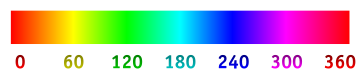

## Wyliczenie danych wyjściowych

W obrazie kolor zapisany jest jako mieszanina składowych modelu tzw. addytywnego, czerwonego, zielonego, niebieskiego - RGB. Konwersja polega na kilku prostych obliczeniach.

Poniższy kod najpierw uśrednia wartości R,G,B po wszytkich pikselach obrazu, następnie sprawdza, która ze średnich składowych jest maksymalna i od tego uzależnia sposób wyliczenia 'hue'. Jeśli obraz jest szary, wartości RGB są sobie równe, minimum jest równe maksimum, to domyślnie 'hue' przyjmuje wartość 0.

In [10]:
def getHueLabels(dataset):
    color_labels=[1,2,3] #r g b
    datasetsize=dataset.shape[0]
    labels_color=np.zeros(datasetsize,dtype=int)
    for probka in range(datasetsize):
        # średnia r, g, b po wszystkich pikselach
        kolory=sum(dataset[probka][0])/(255)

        # obliczenia do konwersji z r, g, b na Hue (odcień)
        maksimum=max(kolory)
        minimum=min(kolory)
        if maksimum==minimum:
            continue #przerwać tę iterację for, Hue równy domyślne zero

        mmscale = 1/(maksimum-minimum)

        indeks=np.where(kolory==maksimum)[0][0]

        if indeks == 0: #red
            Hue = (kolory[1]-kolory[2])*mmscale
        if indeks == 1: #green
            Hue = 2.0 + (kolory[2]-kolory[0])*mmscale
        if indeks == 2: #blue
            Hue = 4.0 + (kolory[0]-kolory[1])*mmscale
        Hue = Hue * 60
        if Hue < 0:
            Hue = Hue + 360;
        labels_color[probka]=np.floor(Hue)
    return(labels_color.reshape(datasetsize,1))

Powyżej zdefiniowana funkcja użyta jest do wyliczenia z obrazów nowych wartości wyjściowych do treningu i testu. W colab przetworzenie 60000 obrazów zajmie około 3 sekundy.

In [11]:
labels_color_train = getHueLabels(dataset = x_train)
labels_color_test = getHueLabels(dataset = x_test)

Sprawdzić można format uzyskanych danych i ich rozmiar.

In [12]:
print(labels_color_train[0:25])
print(y_train[0:25])
print(labels_color_train.shape)
print(y_train.shape)

[[ 29]
 [123]
 [ 17]
 [ 41]
 [223]
 [ 17]
 [ 84]
 [156]
 [205]
 [ 13]
 [ 79]
 [216]
 [202]
 [  6]
 [210]
 [208]
 [201]
 [ 53]
 [350]
 [ 45]
 [180]
 [353]
 [ 28]
 [ 36]
 [ 43]]
[6 9 9 4 1 1 2 7 8 3 4 7 7 2 9 9 9 3 2 6 4 3 6 6 2]
(50000, 1)
(50000,)


Porównajmy wyliczone nowe wartości (25 wartości hue i klas przedmiotów - powyżej) wyjściowe z treścią i kolorystyką obrazów.

Dla przypomnienia: kolejne klasy numerowane od zero to: airplanes, cars, birds, cats, deer, dogs, frogs, horses, ships, trucks.

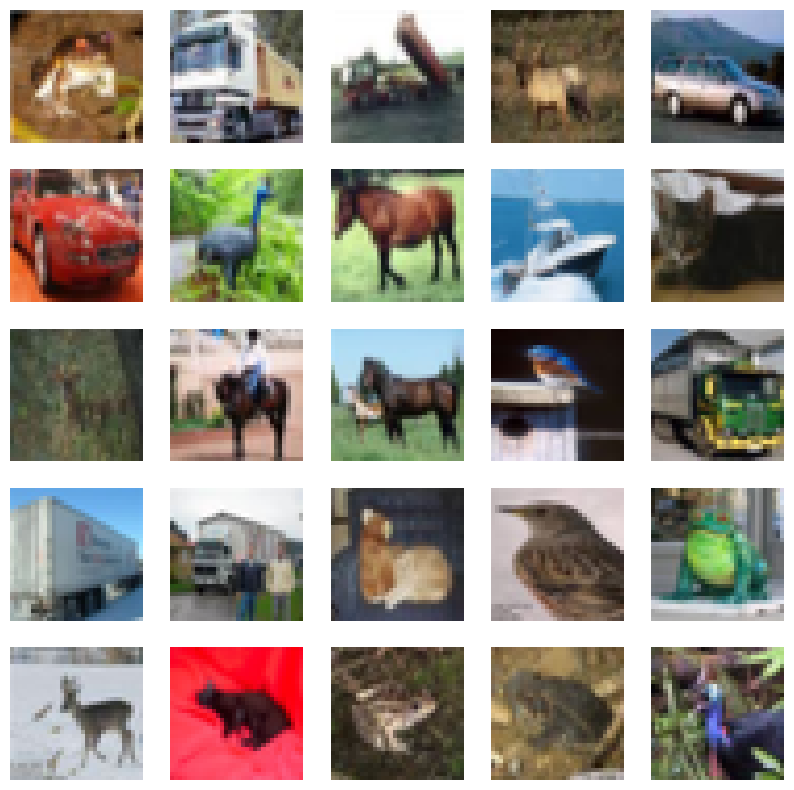

In [13]:
fig, axes = pyplot.subplots(5,5,figsize=(10,10))
for j in range(5):
    for k in range(5):
        i = j*5+k
        axes[j][k].set_axis_off()
        axes[j][k].imshow(x_train[i:i+1][0])


# Model jednozadaniowy: regresja koloru

Należy zapoznać się z przykładową architekturą zdefiniowaną poniżej. Przedyskutuj dobór typów i rozmiaru warstw. Zaproponuj dowolne zmiany kierując się własną intuicją.

Model: "hue_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       196,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 198,785 (776.50 KB)

 Trainable params: 198,785 (776.50 KB)

 Non-trainable params: 0 (0.00 B)

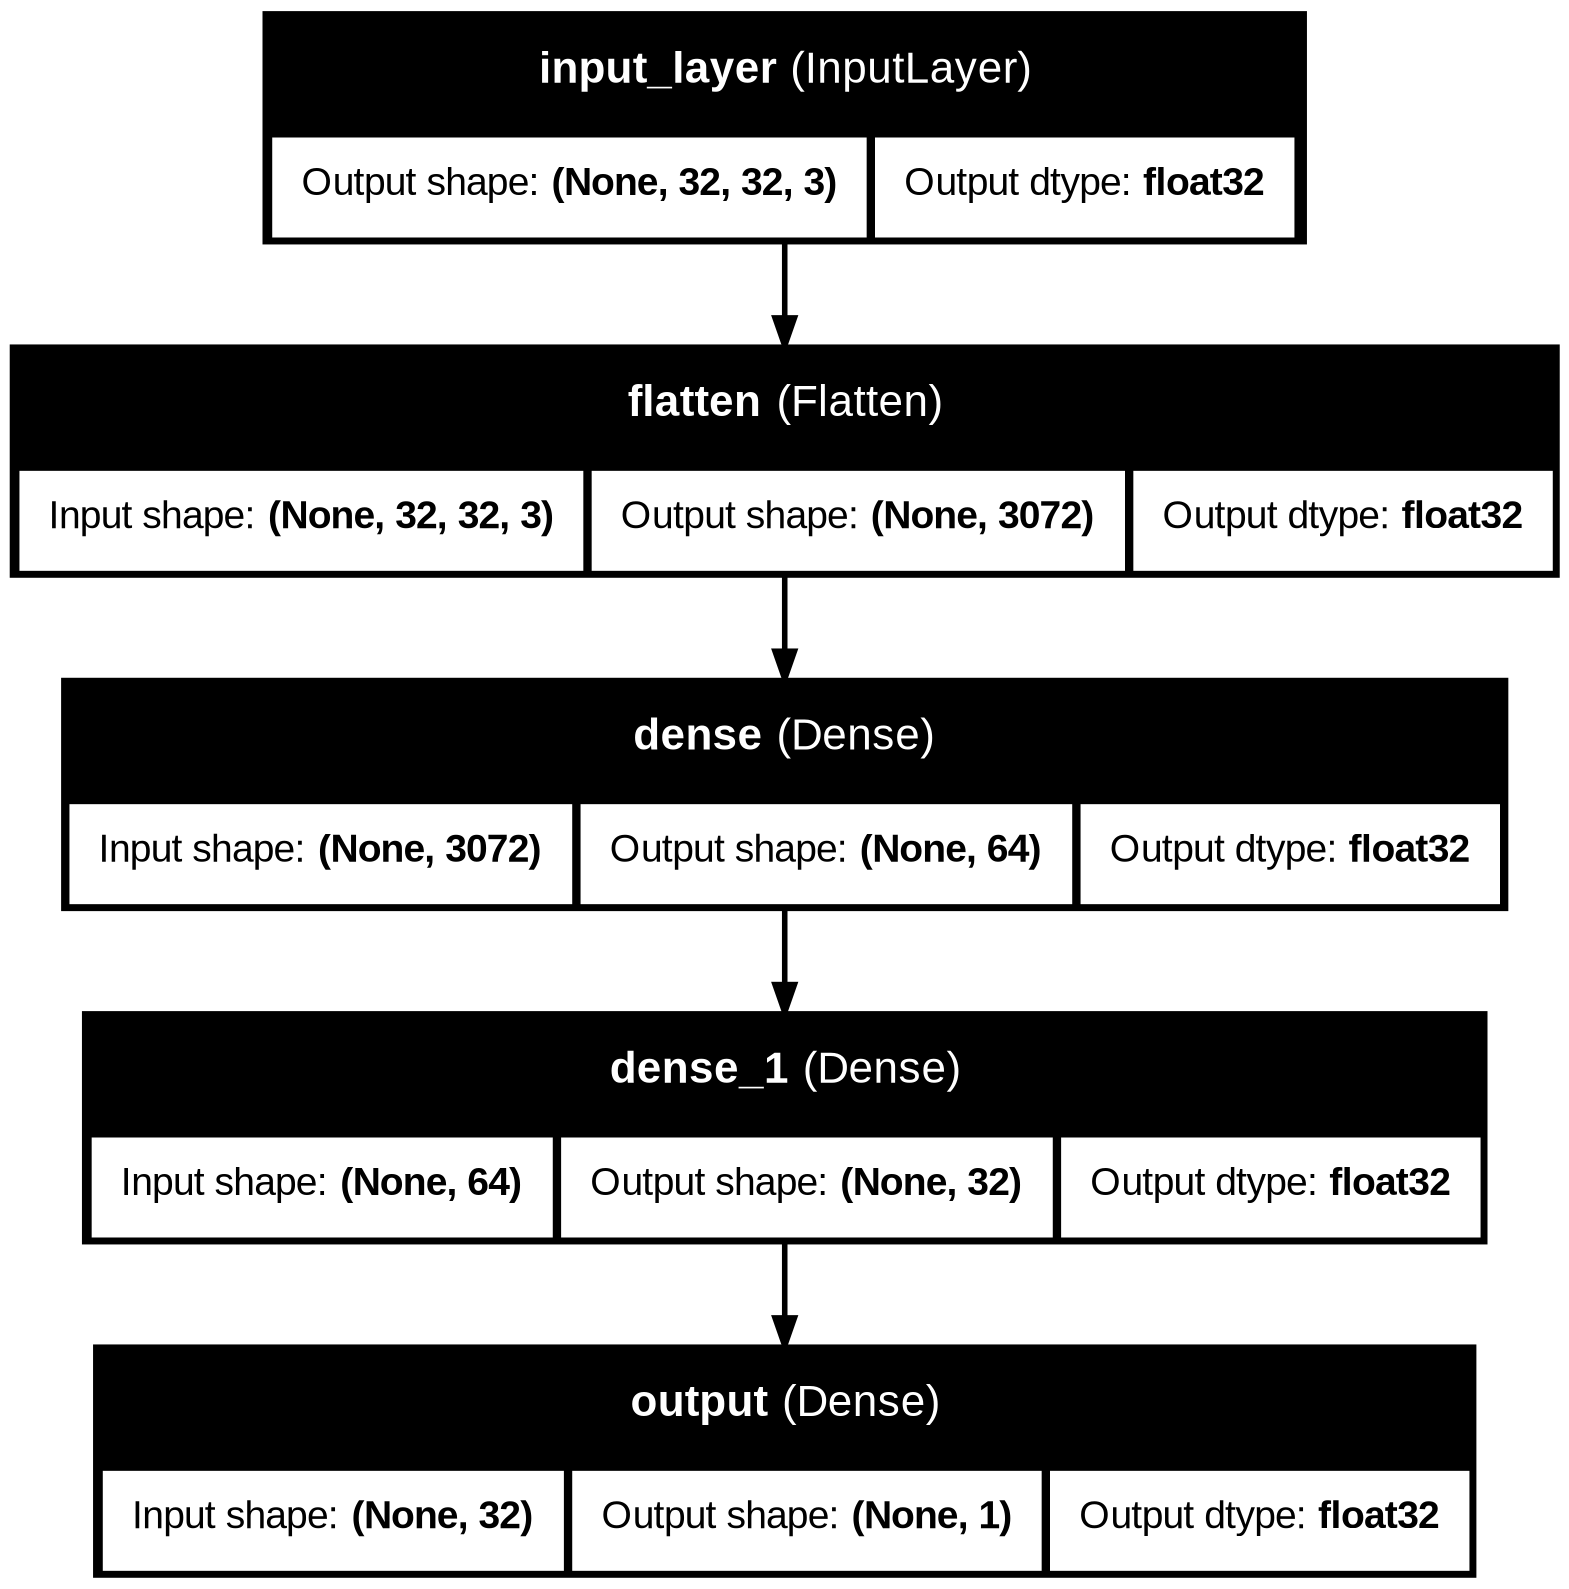

In [14]:
inputs = keras.Input(shape=(32,32,3))      # warstwa wejściowa

#x = layers.Conv2D(filters = 3,kernel_size=3)(inputs)
#x = layers.MaxPooling2D(pool_size=(2, 2), strides=(2,2))(x)
x = layers.Flatten()(inputs)
x = layers.Dense(64, activation="relu")(x) # warstwa ukryta
x = layers.Dense(32, activation="relu")(x) # warstwa ukryta
outputs = layers.Dense(1, name="output")(x)    # wyjście


model = keras.Model(inputs=inputs, outputs=outputs, name="hue_model")
model.summary()
keras.utils.plot_model(model, show_shapes=True, show_layer_names=True,
           show_dtype=True)


Przykładowy `optimizer` z zadanym `lr` oraz `loss` i metryka są następujące:

In [15]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.01),
    #optimizer='sgd',
    loss='mse',
    metrics=[keras.metrics.MeanSquaredError()],
)

## Trening modelu

W celu szybkiego treningu modelu, który może mieć 200000 wag, zaleca się przełączenie środowiska wykonawczego na GPU.

In [16]:
history = model.fit(x_train, labels_color_train, batch_size=64, epochs=10, validation_split=0.2)

#test_scores = model.evaluate(x_test, labels_color_test, verbose=2)
#print("Test loss:", test_scores[0])
#print("Test accuracy:", test_scores[1])

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - loss: 7072.4937 - mean_squared_error: 7072.4937 - val_loss: 6463.1738 - val_mean_squared_error: 6463.1738
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 6316.6216 - mean_squared_error: 6316.6216 - val_loss: 5969.1602 - val_mean_squared_error: 5969.1602
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 5873.4072 - mean_squared_error: 5873.4072 - val_loss: 6028.6758 - val_mean_squared_error: 6028.6758
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 5594.1582 - mean_squared_error: 5594.1582 - val_loss: 4946.9902 - val_mean_squared_error: 4946.9902
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 4825.3872 - mean_squared_error: 4825.3872 - val_loss: 4641.9810 - val_mean_squared_error: 4641.9810
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 4711.0962 - mean_squared_error: 4711.0962 - val_loss: 4313.9121 - val_mean_squared_error: 4313.9121
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 

## Ocena modelu

Zaobserwować należy przebieg zmian `loss`.

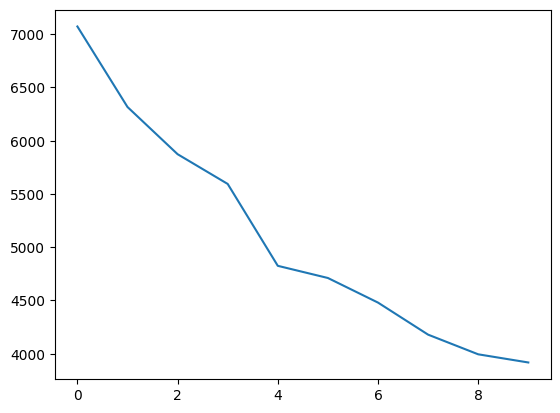

In [17]:
pyplot.plot(history.history['loss'])

Wynik ewaluacji na całym zbiorze testowym.

In [18]:
model.evaluate(x_test,labels_color_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 4430.2808 - mean_squared_error: 4430.2808


[4430.28076171875, 4430.28076171875]

Rozważyć należy jaki jest faktyczny błąd, jeśli pod koniec treningu średni błąd kwadratowy wynosi kilka tysięcy.

Zbadać można jaki jest wynik dla wybranego obrazu ze zbioru testowego(wyświetlana jest wartość przewidywana przez model oraz prawdziwa).

In [19]:
probka=12
result=model.predict(x_test[probka:probka+1,])
print(result[0])
print(labels_color_test[probka])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 454ms/step
[51.182335]
[39]


## Zadanie do wykonania

Należy zmodyfikować model, dodając np. warstwy dropout, zmieniając liczbę neuronów w warstwach i liczbę warstw. Zastosować można także (jako pierwszą warstwę) warstwę splotową. Ostatecznie uzyskany model powinien osiągać zadawalającą dokładność regresji wartości `hue` oraz nie być nadmiernie złożony.

Znaczenie określenia "nadmierna złożoność" powinno wynikać z intuicyjnego rozumienia zadania, które model ma realizować. Dane wyjściowe powyżej zostały za pomocą bardzo prostego algorytmu wygenerowane na podstawie pikseli obrazu. Wymagały sumowania (trzy razy 1024), znalezienia maksimum i minimum w wektorze 3 wartości, sumy i dzielenia. Model o podobnych możliwościach nie powinien zawierać więcej niż kilkanaście tysięcy wag.

# Model jednozadaniowy: klasyfikacja obrazu siecią splotową

Na potrzeby klasyfikacji i poprawnego wyliczania loss i accuracy dane wyjściowe zmienione zostaną z kodowania wprost na kodowanie one-hot.

In [20]:
nb_classes = 10 # number of unique image classes

Y_train = keras.utils.to_categorical(y_train, nb_classes)
Y_test = keras.utils.to_categorical(y_test, nb_classes)
print(Y_train[0:5])

[[0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]]


Poniżej jako argumenty do definicji warstw podawane są nienazwane parametry, jednakże zachowana jest kolejność:

- pierwszy argument - liczba filtrów,
- drugi argument - rozmiar kwadratowego kernela, np. 3 oznacza 3x3.

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ img (InputLayer)                │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 9, 9, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 9, 9, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 9, 9, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │        16,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 112,458 (439.29 KB)

 Trainable params: 112,458 (439.29 KB)

 Non-trainable params: 0 (0.00 B)

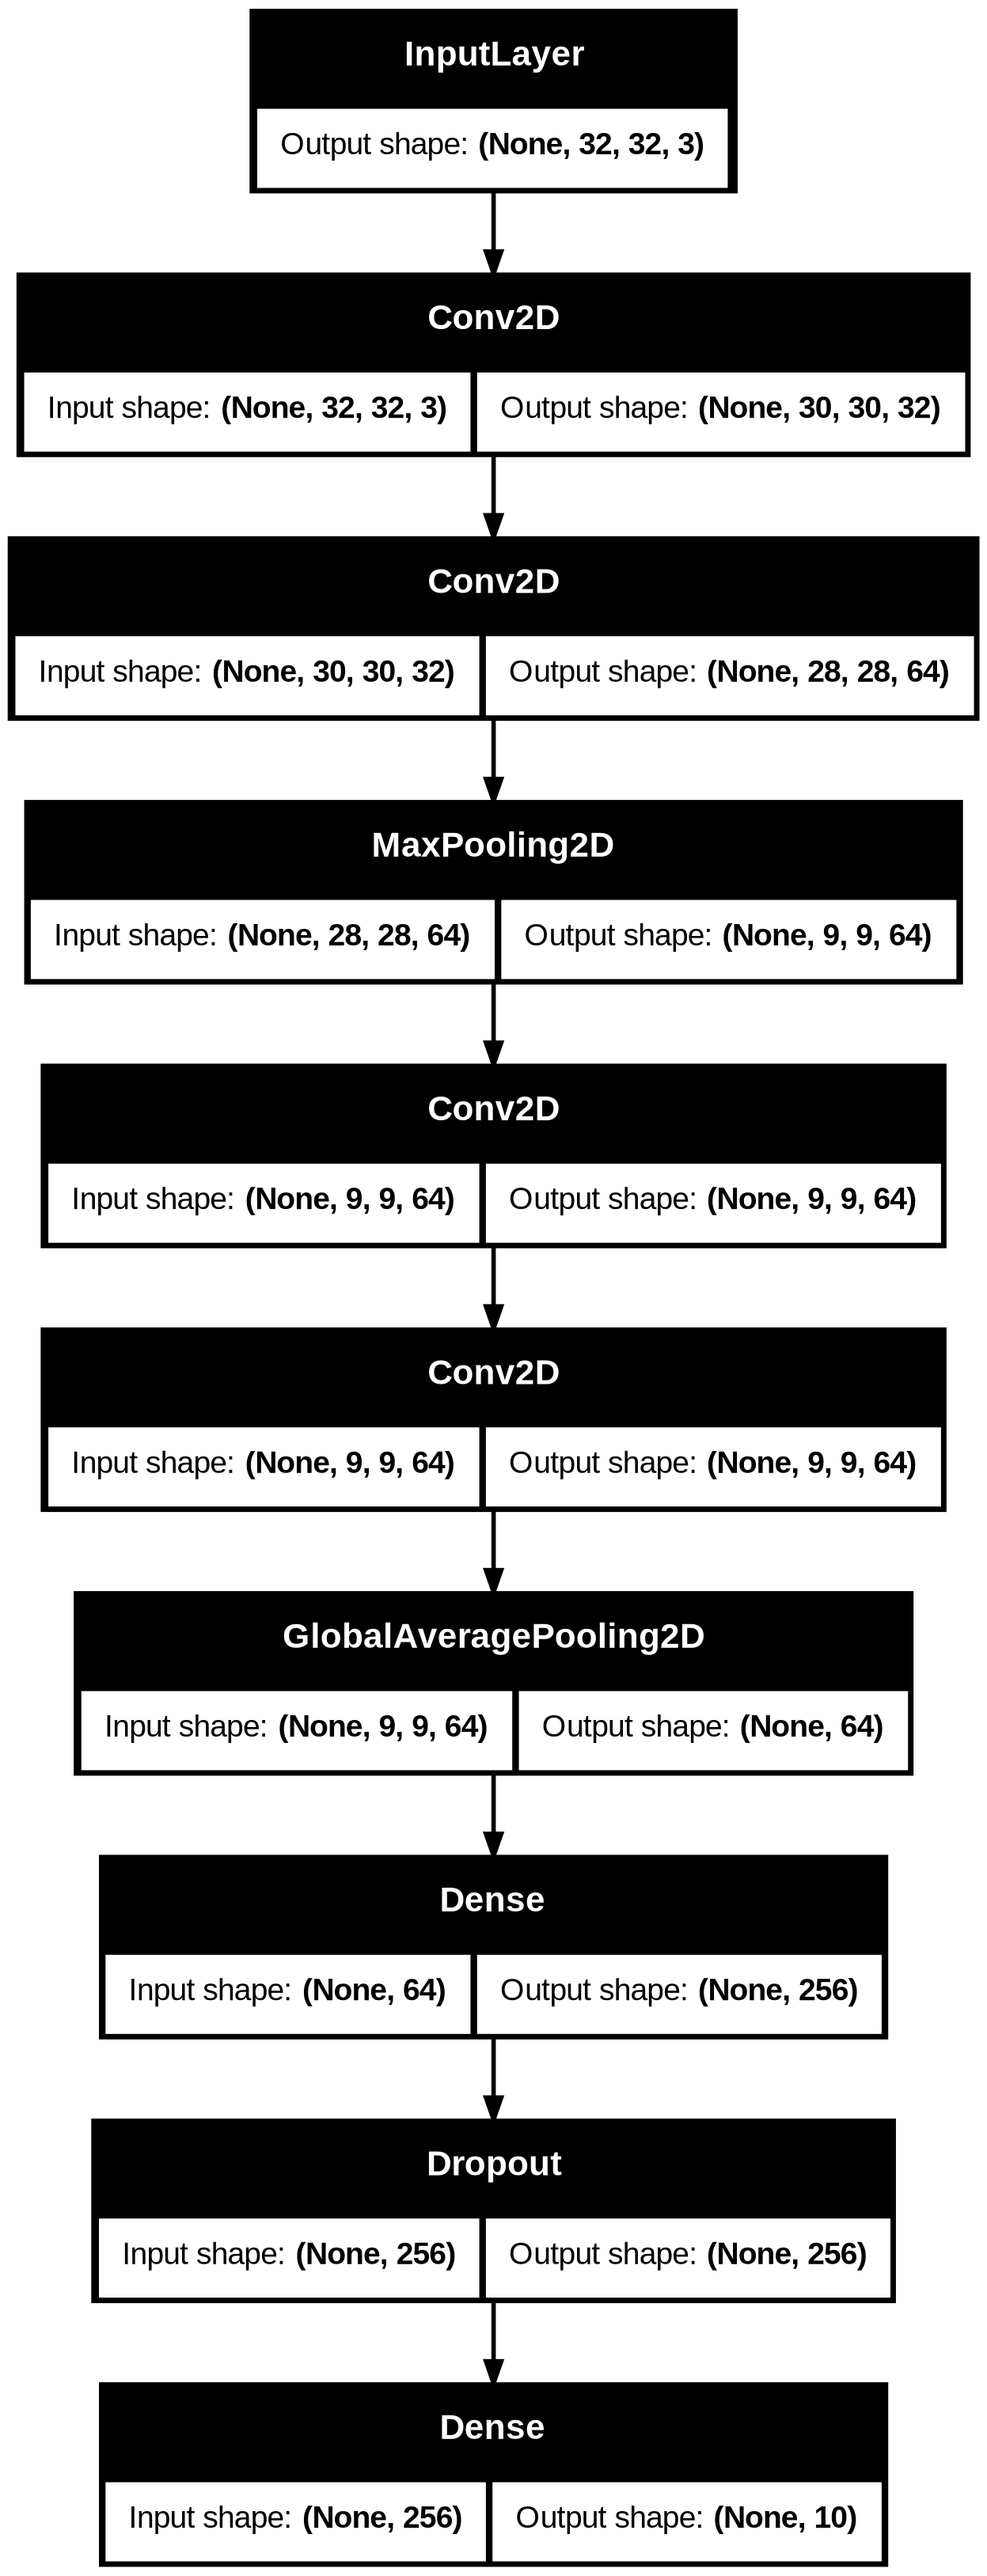

In [21]:
inputs_im = keras.Input(shape=(32, 32, 3), name="img")
# layers.Conv2D - własne zadanie: sprawdzić dokumentację przez użycie 'tooltip' i autouzupełniania
x_im = layers.Conv2D(32, 3, activation="relu")(inputs_im)
x_im = layers.Conv2D(64, 3, activation="relu")(x_im)
x_im = layers.MaxPooling2D(3)(x_im)

x_im = layers.Conv2D(64, 3, activation="relu", padding="same")(x_im)
x_im = layers.Conv2D(64, 3, activation="relu", padding="same")(x_im)
x_im = layers.GlobalAveragePooling2D()(x_im)

x_im = layers.Dense(256, activation="relu")(x_im)
x_im = layers.Dropout(0.5)(x_im)
outputs_im = layers.Dense(10)(x_im)

model_im = keras.Model(inputs_im, outputs_im)
model_im.summary()
keras.utils.plot_model(model_im, show_shapes=True)

In [22]:
model_im.compile(
    optimizer=keras.optimizers.RMSprop(1e-3),
    loss=keras.losses.CategoricalCrossentropy(from_logits=True),
    metrics=["acc"],
)

## Trening i ocena modelu

Uwaga: dane wyjściowe one-hot nazwane są zmienną `Y_train` i `Y_test` (wielką literą, w odróżnieniu od `y_train` i `y_test`, które zawiera int, kodowanie wprost).


Na potrzeby nauki można zmienić środowisko wykonawcze w colab na GPU.

In [23]:
model_im.fit(x_train, Y_train, batch_size=64, epochs=10, validation_split=0.2)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 14s 11ms/step - acc: 0.2329 - loss: 1.9688 - val_acc: 0.3368 - val_loss: 1.7155
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - acc: 0.3612 - loss: 1.6623 - val_acc: 0.4028 - val_loss: 1.5728
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - acc: 0.4407 - loss: 1.4951 - val_acc: 0.4974 - val_loss: 1.3629
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - acc: 0.5079 - loss: 1.3396 - val_acc: 0.5520 - val_loss: 1.2225
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - acc: 0.5580 - loss: 1.2198 - val_acc: 0.5338 - val_loss: 1.3028
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - acc: 0.5935 - loss: 1.1308 - val_acc: 0.6359 - val_loss: 1.0196
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - acc: 0.6232 - loss: 1.0578 - val_acc: 0.6652 - val_loss: 0.9478
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - acc: 0.6479 - loss: 0.9872 - val_acc: 0.6477 - val_loss: 0.9769
Epoch 9/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - 

In [24]:
score = model.evaluate(x_test, Y_test)
print('Test score:', score[0])
print('Test accuracy:', score[1])

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 18851.3398 - mean_squared_error: 18851.3398
Test score: 18851.33984375
Test accuracy: 18851.33984375


## Zadanie do wykonania

Należy model splotowy zmodyfikować i uzasadnić krótko wprowadzone zmiany. Oczekiwane `Test accuracy` jest na poziomie powyżej 0.72.

Należy zwrócić uwagę na `loss` dla obu modeli. Różnią się one o kilka rzędów wielkości i powinno być to odpowiednio zaadresowane doborem wag w uczeniu wielozadaniowym.

# Uczenie wielozadaniowe

Model wielozadaniowy w tym ćwiczeniu laboratoryjnym wykorzystywać będzie pretrenowaną sieć splotową do klasyfikacji obrazu, wykonaną w ostatnim kroku powyżej (`model_im`).


## Modyfikacja pretrenowanego modelu

Raz wytrenowany model można modyfikować, zmieniając jego architekturę. Warstwy, które pozostaną nienaruszone będą miały wartości wag, takie jak obliczone w procesie nauki. Nowe warstwy inicjowane będą losowo.

Aby zmodyfikować model konieczne jest odwoływanie się do jego wybranych warstw. Służy do tego struktura `layers`, zawierająca wszystkie warstwy modelu, iterowalna numerem warstwy.

In [25]:
model_im.layers

[<InputLayer name=img, built=True>,
 <Conv2D name=conv2d, built=True>,
 <Conv2D name=conv2d_1, built=True>,
 <MaxPooling2D name=max_pooling2d, built=True>,
 <Conv2D name=conv2d_2, built=True>,
 <Conv2D name=conv2d_3, built=True>,
 <GlobalAveragePooling2D name=global_average_pooling2d, built=True>,
 <Dense name=dense_2, built=True>,
 <Dropout name=dropout, built=True>,
 <Dense name=dense_3, built=True>]

Poniżej zauważyć można w jaki sposób odwołać się do konkretnej warstwy i odczytać jej pola, np. nazwę.

In [26]:
print(model_im.layers[0].name)
print(model_im.layers[1].name)
print(model_im.layers[2].name)
print(model_im.layers[3].name)
print(model_im.layers[4].name)

img
conv2d
conv2d_1
max_pooling2d
conv2d_2


Metoda `get_layer` wydobywa z modelu warstwę o podanej nazwie. Następnie wyjście tej warstwy można wykorzystać do dobudowania nowych elementów do architektury modelu.

UWAGA: poniższy przykład nie jest związany z rozważanym scenariuszem praktycznym, służy wyłącznie jako zobrazowanie możliwości modyfikacji.

In [27]:
new_layers=(model_im.get_layer('conv2d_2').output)
new_layers=layers.Flatten()(new_layers)
new_layers_A=layers.Dense(1)(new_layers)

new_layers_B=layers.Dense(10)(new_layers)
new_layers_B=layers.Dense(10)(new_layers_B)

model_mod = keras.Model(inputs=inputs_im, outputs=[new_layers_A, new_layers_B], name="temp_model")

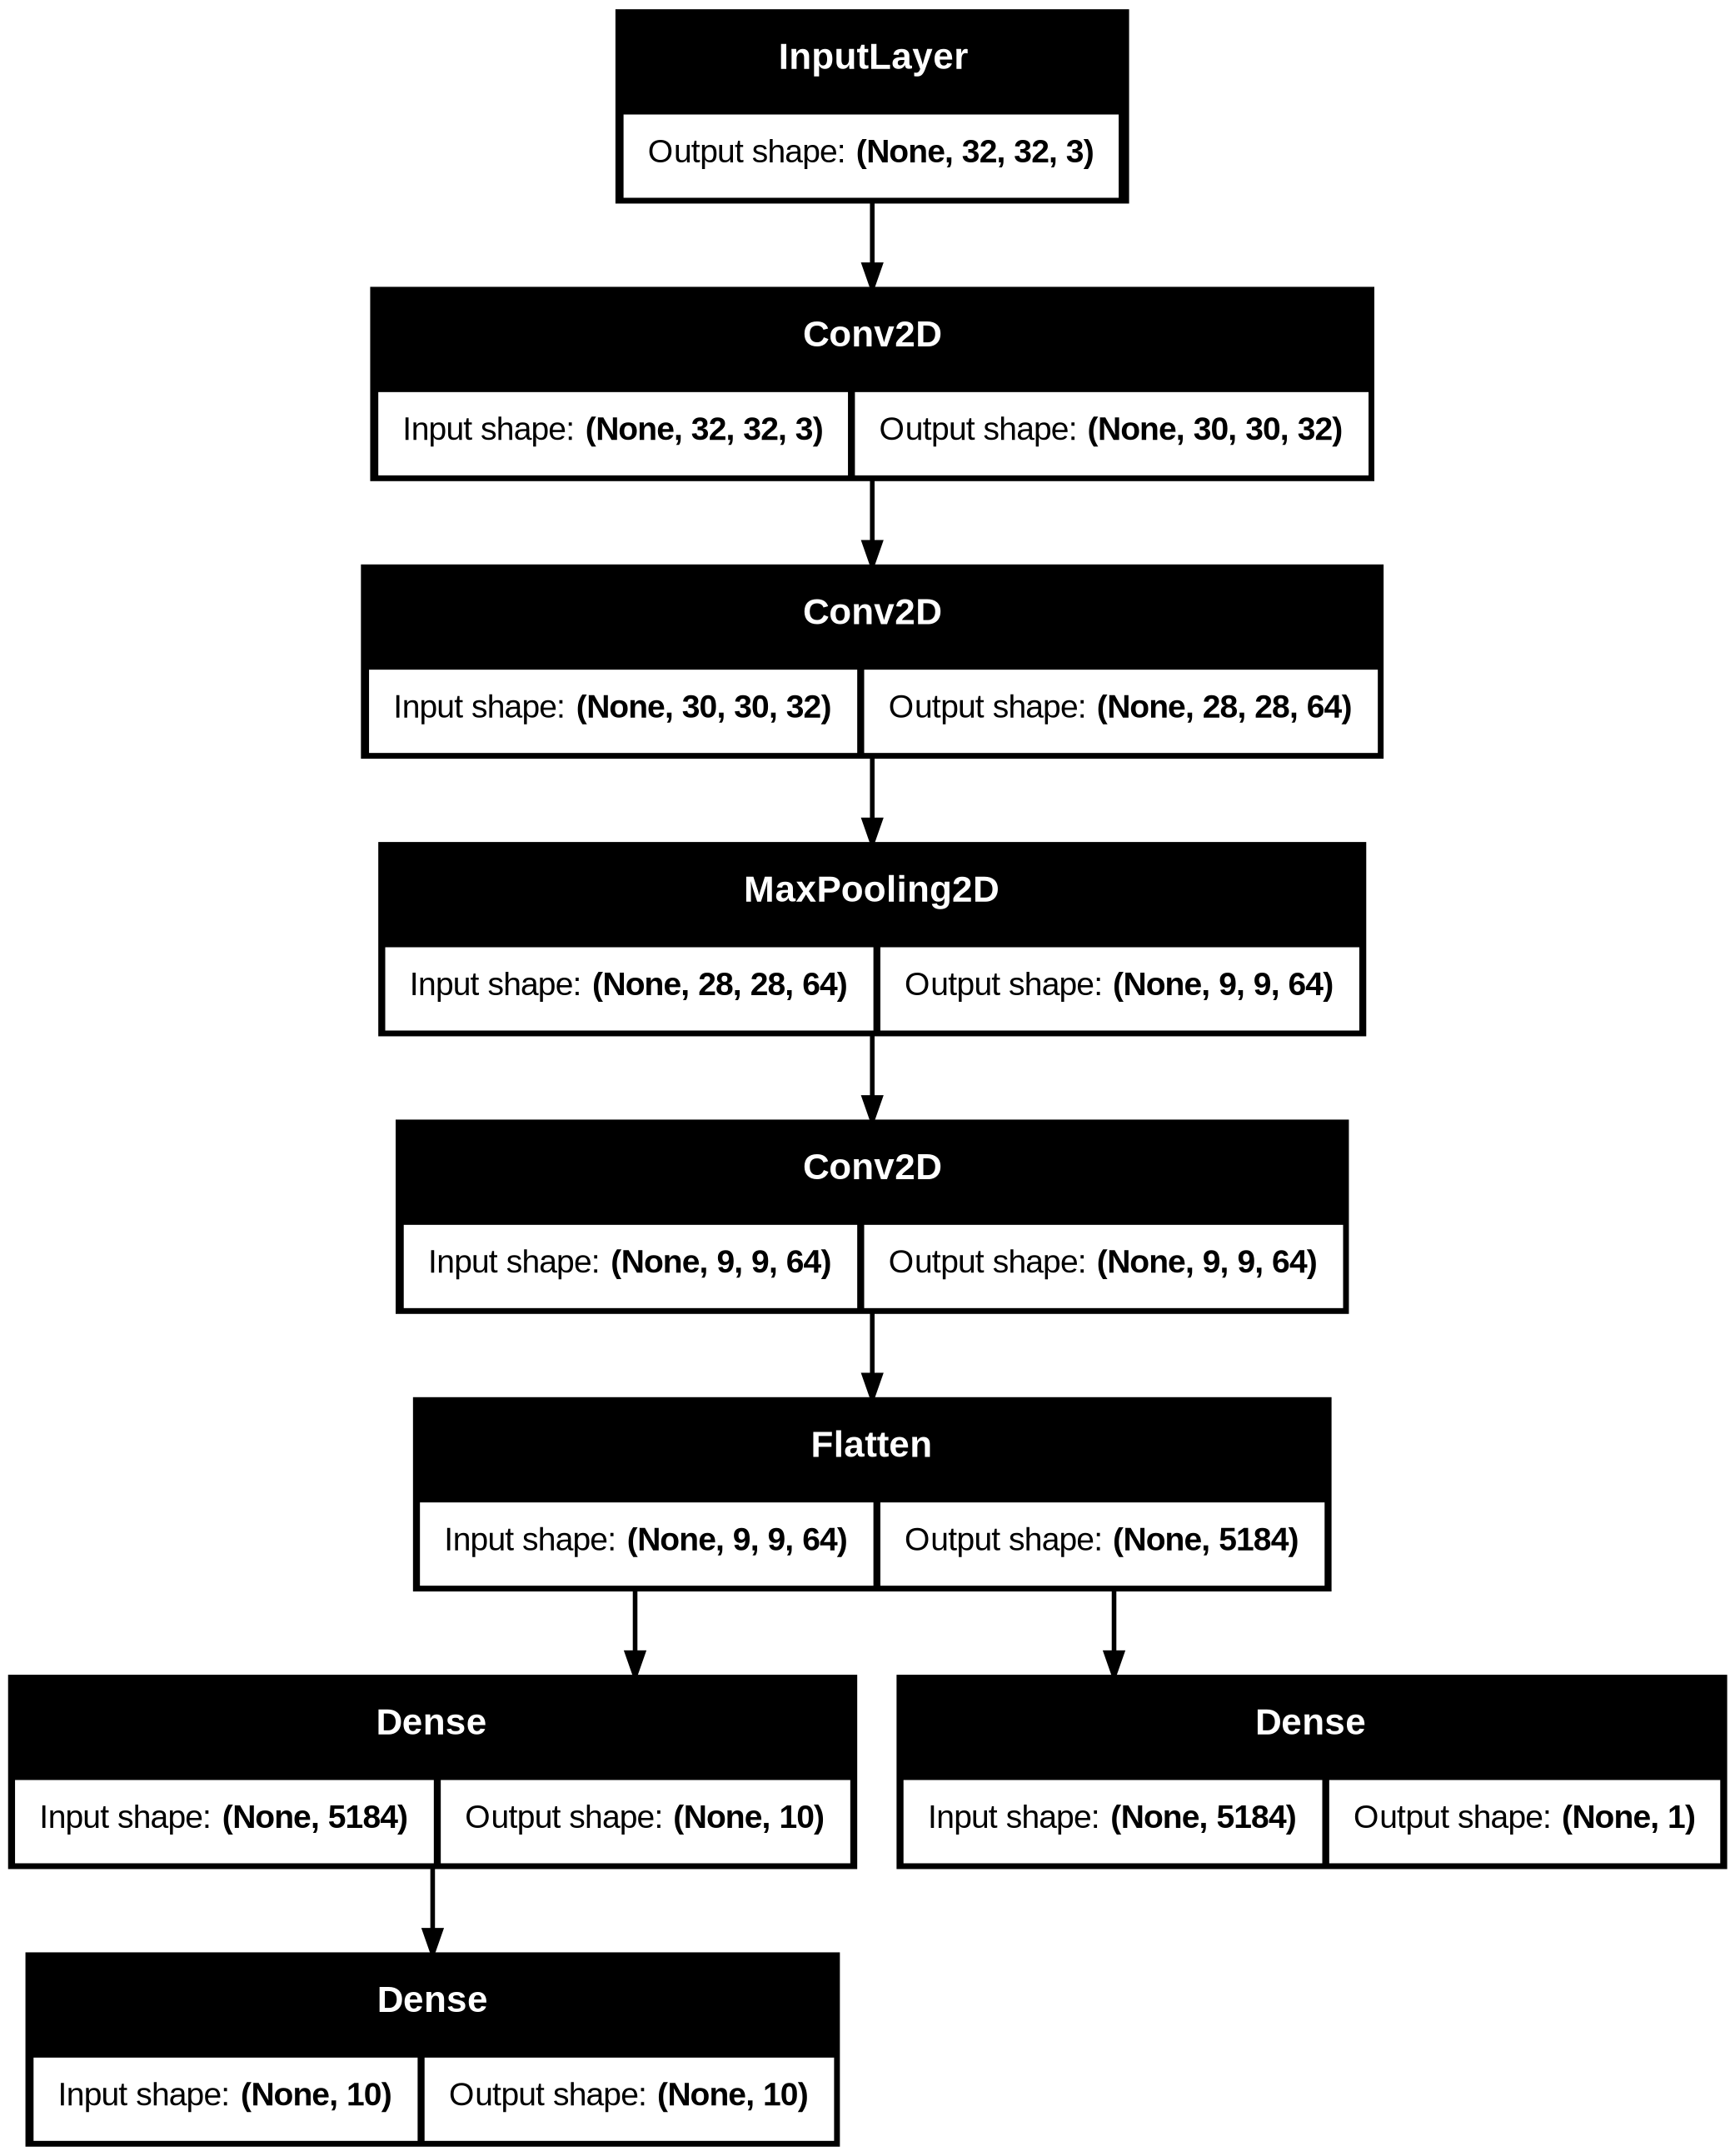

In [28]:
keras.utils.plot_model(model_mod,show_shapes=True)

## Zamrażanie warstw modelu

Jeśli nowa architektura bazować ma na innej, **wcześniej wytrenowanej** do realizacji jednego zadania, to wartości wag współdzielonej cześci nie powinny podlegać istotnym zmianom w dalszych etapach nauki.

Istnieje możliwość zablokowania, "zamrożenia" wartości wag w modelu, poprzez ustawienie pola `trainable` wybranej warstwy. Wszystkie warstwy znajdujące się w modelu powyżej niej wyłączone zostaną z optymalizacji wag.

In [29]:
model_mod.layers[2].trainable = True #domyślnie po utworzeniu modelu wszytkie warstwy mają True
print(model_mod.layers[2].trainable)
model_mod.layers[2].trainable = False
print(model_mod.layers[2].trainable)


True
False


UWAGA: Jeśli już model był zdefiniowany, skompilowany, uczony, a następnie zmodyfikowany i wybrane warstwy zostały zamrożone, to należy ponownie wykonać `compile`.

In [30]:
model_mod.compile(
    optimizer=keras.optimizers.RMSprop(1e-3),
    loss=[keras.losses.mean_squared_error ,keras.losses.CategoricalCrossentropy(from_logits=True)],
    metrics=["acc"],
)

## Trening z zamrażaniem warstw

Dokumentacja biblioteki `Keras` opisuje wiele możliwości i podejść do treningu modelu do nowych zadań (uczenia transferowego): https://keras.io/guides/transfer_learning/.

To laboratorium nie dotyczy dokładnie uczenia transferowego, gdyż zakładamy, że początkowe zadanie cały czas ma być realizowane. Nie następuje zmiana dziedziny działania modelu, ale jej rozszerzenie o dodatkowe zadanie. Jednakże wytyczne zwiazane z uczeniem transferowym mają zastosowanie także w tym przypadku.

Zalecane jest przestrzeganie następującego scenariusza:

- model jednozadaniowy dla zadania bardziej złożonego jest definiowany i trenowany
- model ten rozbudowywany jest o nowe elementy do postaci wielozadaniowego modelu
- warstwy współdzielone między zadaniami powinny zostać zamrożone
- trenować należy w scenariuszu uczenia wielozadaniowego z `lr` dobranym jako wypadkowa między wartościami zalecanymi dla obu zadań
- w ostatnim kroku należy odblokować warstwy, ustawiając `trainable` na `True` i kontynuować trening z **bardzo małą wartością parametru** `lr`.

Dzieki powyższemu zapewnia się zachowanie wartości wag odpowiedzialnych za poprawne działanie dla pierwszego, bardziej złożonego zadania oraz celowe trenowanie elementów architektury odpowiedzialnych za drugie zadanie.



## Dobór hiperparametrów

W kodzie powyżej używane były przykładowe `optimizer` oraz `loss`. Można zaproponować własne lub uzasadnić obecny wybór, kierując się opisami:

- dobór metryki https://keras.io/api/metrics/
- dobór loss https://keras.io/api/losses/





# Zadanie do wykonania

Należy przygotować kod realizujący opisany powyżej scenariusz "Treningu z zamrażaniem warstw". Zadaniem głównym powinna być klasyfikacja obrazu, architektura to sieć splotowa, głęboka, odpowiednio wykorzystująca warstwy typu conv2d, pooling, dropout, flattening i dense.

Należy zidentyfikować w modelu miejsce dodania rozgałęzienia, odpowiedniego do realizacji drugiego zadania i rozbudować architekturę. W trakcie kompilacji modelu użyć należy właściwych wartości `loss_weights`.

Należy poprawnie wykorzystać zamrażanie warstw, trening z odpowiednią wartością `lr`, odmrożenie warstw, trening z bardzo małą wartoscią `lr`.

Po każdym etapie treningu należy wykreślać i obserwować `loss` oraz `test accuracy`.

-----

<center><img src='https://drive.google.com/uc?id=1PioHCAlQTt8LWChoMysPErSOrxOfAW0R'></center>